# 08 · Report exhibits: the GoldPulse Index, and does the crowd lead or follow gold?

Presentation follows Semenova et al. (2024), *Wisdom of the Crowds or Ignorance of the Masses? A Data-Driven
Guide to WallStreetBets*, Journal of Portfolio Management 50(4): numbered exhibits with notes, an event study
of returns around posts (their Exhibit 5), return statistics of trading on the crowd (Exhibit 6) and Granger
causality tests (Exhibit 7). Their topic-model and network clustering is **not** reproduced: it is unsupervised.
Nothing here trains a model; these are descriptive statistics and classical tests.

Data: `data/clean/goldpulse_index.parquet` (public index, Reddit + Yahoo) and `data/bbg/daily_features.parquet`
(Bloomberg XAU closes aligned to the 20:00 UTC Reddit day, git-ignored).

### What would count, fixed before running
* **Reactive crowd (event study):** gold's mean 7-day return *before* attention spikes is above its usual 7-day
  return (t-test p < 0.05), while the 7-day return *after* is not.
* **Leading crowd (Granger):** a Reddit series Granger-causes gold returns at p < 0.003 (Bonferroni, 16 tests:
  2 Reddit series × 2 directions × 4 lags). Gold → Reddit is tested at the same bar.
* **Tradable crowd (returns):** a follow-the-crowd rule earns a next-day mean return different from zero *and*
  from buy-and-hold at p < 0.0125 (Bonferroni, 4 rows).

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

from scipy import stats
index = pd.read_parquet("data/clean/goldpulse_index.parquet")
daily = pd.read_parquet("data/bbg/daily_features.parquet")
daily["r"] = np.log(daily["xau_close"]).diff()            # log return, close d-1 -> close d
daily["r_next"] = daily["r"].shift(-1)                     # close d -> close d+1 (the future)
EXHIBITS = Path("reports/exhibits"); EXHIBITS.mkdir(parents=True, exist_ok=True)
pub = index.dropna(subset=["attention_score"])
print(f"Index: {len(pub)} published days, {pub.index.min():%Y-%m-%d} -> {pub.index.max():%Y-%m-%d}")
print(pub["attention_band"].value_counts(normalize=True).round(3).to_string())

Index: 1494 published days, 2022-09-02 -> 2026-10-04
attention_band
Normal    0.537
Quiet     0.219
Busy      0.159
Frenzy    0.084


## Exhibit 1 · The GoldPulse Index vs. the gold price, 2022–2026

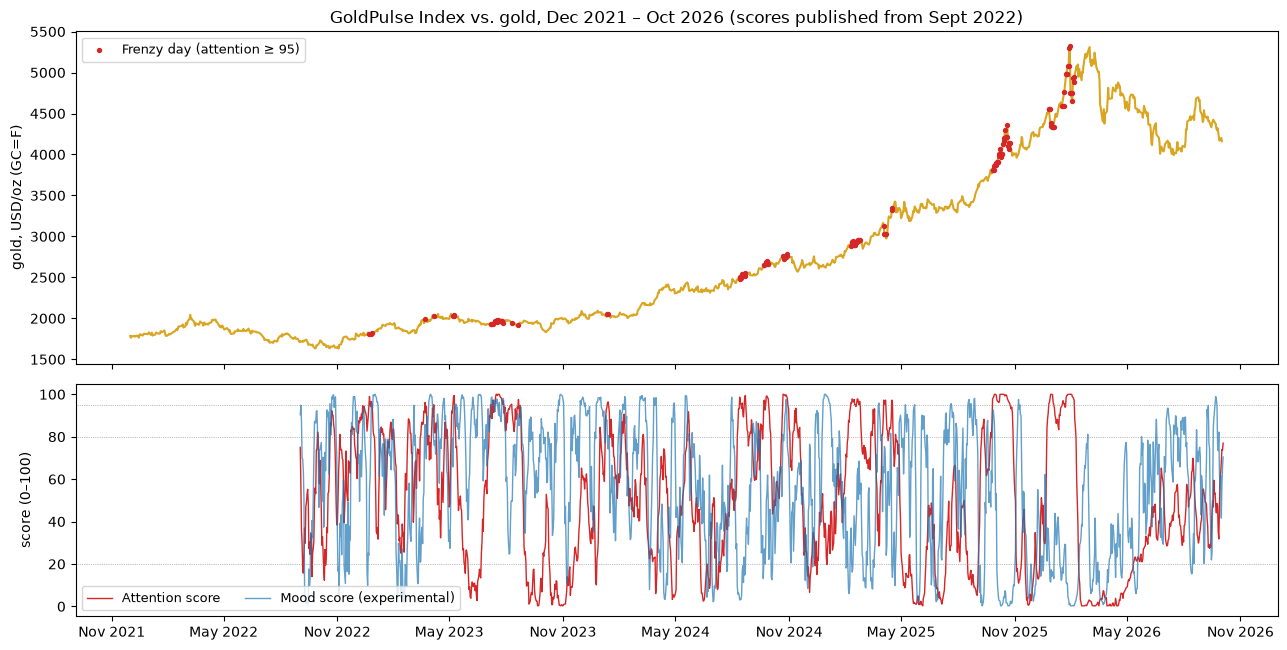

In [2]:
import matplotlib.dates as mdates
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True, gridspec_kw={"height_ratios": [2, 1.4]})
gold = index["gold_close"].dropna()
ax1.plot(gold.index, gold, color="goldenrod", lw=1.5)
ax1.set_ylabel("gold, USD/oz (GC=F)")
frenzy = pub.index[pub["attention_band"] == "Frenzy"]
ax1.scatter(frenzy, index["gold_close"].ffill().reindex(frenzy), s=8, color="tab:red", zorder=3, label="Frenzy day (attention ≥ 95)")
ax1.legend(loc="upper left", fontsize=9)
ax1.set_title("GoldPulse Index vs. gold, Dec 2021 – Oct 2026 (scores published from Sept 2022)")
ax2.plot(pub.index, pub["attention_score"], color="tab:red", lw=1, label="Attention score")
ax2.plot(pub.index, pub["mood_score"], color="tab:blue", lw=1, alpha=0.7, label="Mood score (experimental)")
for y in (20, 80, 95):
    ax2.axhline(y, color="gray", lw=0.5, ls=":")
ax2.set_ylabel("score (0–100)")
ax2.legend(loc="lower left", fontsize=9, ncol=2)
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
fig.savefig(FIGURES / "exhibit_1_index_vs_gold.png", dpi=150, bbox_inches="tight")

## Exhibit 2 · Gold's path 14 trading days before and after a Reddit attention spike
Spike = a trading day whose chatter (`attention_spike`: posts per day vs. their trailing 20-day mean) is in the top 5%
of days. Spikes within 10 trading days of an earlier one are merged into it (first day kept), so one episode counts once.
The path is the cumulative log return relative to the spike day's close (0 on day 0).

24 spike episodes (threshold: attention_spike >= 0.26, i.e. ~30% above its 20-day norm)


,n,mean %,usual 7-day mean %,share up,t,p
window,,,,,,
7 days before spike,24,1.027,0.488,0.667,0.896,0.379
7 days after spike,24,-0.054,0.488,0.458,-1.001,0.327


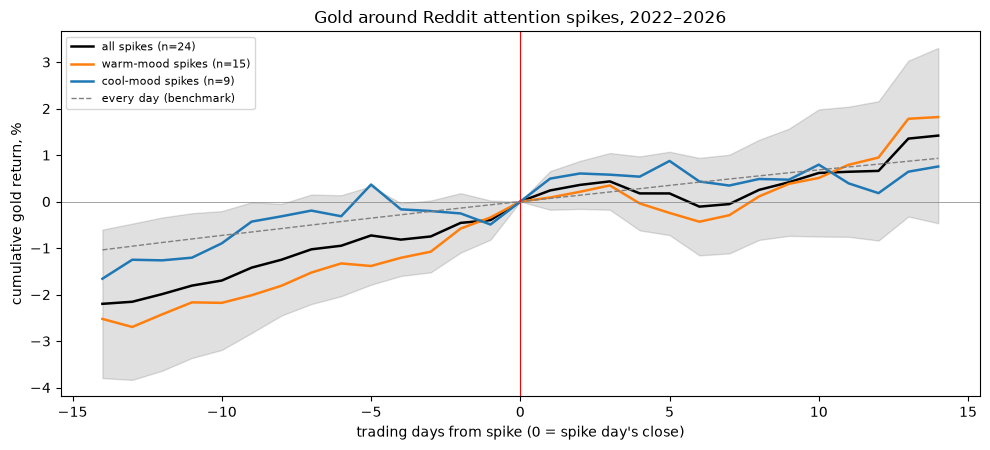

In [3]:
d = daily.dropna(subset=["attention_spike", "r"])
cut = d["attention_spike"].quantile(0.95)
events, last = [], None
for i, t in enumerate(d.index):
    if d.at[t, "attention_spike"] >= cut and (last is None or i - last > 10):
        events.append(i)
    if d.at[t, "attention_spike"] >= cut:
        last = i
W = 14
logp = np.log(d["xau_close"]).to_numpy()
paths = np.array([logp[i - W:i + W + 1] - logp[i] for i in events if i - W >= 0 and i + W < len(d)])
ev_days = [d.index[i] for i in events if i - W >= 0 and i + W < len(d)]
mood_med = d["mean_sentiment"].rolling(250, min_periods=60).median()
warm = np.array([d.at[t, "mean_sentiment"] > mood_med.at[t] for t in ev_days])
print(f"{len(paths)} spike episodes (threshold: attention_spike >= {cut:.2f}, i.e. ~{np.expm1(cut):.0%} above its 20-day norm)")

# Unconditional benchmark: the same paths around every day.
all_idx = np.arange(W, len(d) - W)
base = np.array([logp[i - W:i + W + 1] - logp[i] for i in all_idx])
k = np.arange(-W, W + 1)
fig, ax = plt.subplots(figsize=(10, 4.6))
for sel, lab, col in [(slice(None), f"all spikes (n={len(paths)})", "black"),
                      (warm, f"warm-mood spikes (n={warm.sum()})", "tab:orange"),
                      (~warm, f"cool-mood spikes (n={(~warm).sum()})", "tab:blue")]:
    m = paths[sel].mean(0); se = paths[sel].std(0, ddof=1) / np.sqrt(len(paths[sel]))
    ax.plot(k, m * 100, color=col, lw=1.8, label=lab)
    if lab.startswith("all"):
        ax.fill_between(k, (m - 1.96 * se) * 100, (m + 1.96 * se) * 100, color=col, alpha=0.12)
ax.plot(k, base.mean(0) * 100, color="gray", ls="--", lw=1, label="every day (benchmark)")
ax.axvline(0, color="red", lw=0.8); ax.axhline(0, color="gray", lw=0.5)
ax.set_xlabel("trading days from spike (0 = spike day's close)"); ax.set_ylabel("cumulative gold return, %")
ax.set_title("Gold around Reddit attention spikes, 2022–2026")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "exhibit_2_event_study.png", dpi=150, bbox_inches="tight")

before = -paths[:, W - 7]          # log(P0 / P-7)
after = paths[:, W + 7]            # log(P7 / P0)
ret7 = pd.Series(logp).diff(7).dropna().to_numpy()
rows = []
for name, x in [("7 days before spike", before), ("7 days after spike", after)]:
    t, p = stats.ttest_1samp(x, ret7.mean())
    rows.append({"window": name, "n": len(x), "mean %": x.mean() * 100, "usual 7-day mean %": ret7.mean() * 100,
                 "share up": (x > 0).mean(), "t": t, "p": p})
event_table = pd.DataFrame(rows).set_index("window")
event_table.round(3).to_csv(EXHIBITS / "exhibit_2_event_study.csv")
event_table.round(3)

## Exhibit 3 · Distribution of next-day gold returns when following the crowd
Statistics of the next-day log return (close d → close d+1) for each rule, against buy-and-hold. "Warm mood" = the
day's mean VADER above its trailing 250-day median (no look-ahead). "Previous" = the return on the spike day itself,
which shows whether the crowd talks *after* moves (as in the paper's Exhibit 6).

In [4]:
valid = d.dropna(subset=["r_next"]).copy()
valid["warm"] = valid["mean_sentiment"] > mood_med.reindex(valid.index)
valid["spike"] = valid["attention_spike"] >= cut
rules = {
    "buy and hold (every day)": valid["r_next"],
    "follow the mood: long if warm, short if cool": np.where(valid["warm"], 1, -1) * valid["r_next"],
    "long only on warm-mood days": valid.loc[valid["warm"], "r_next"],
    "after an attention spike (next day)": valid.loc[valid["spike"], "r_next"],
    "previous: the spike day itself": valid.loc[valid["spike"], "r"],
}
bh = valid["r_next"]
rows = []
for name, x in rules.items():
    x = pd.Series(x, index=valid.index if len(x) == len(valid) else None).dropna()
    t0, p0 = stats.ttest_1samp(x, 0)
    row = {"rule": name, "n days": len(x), "mean (bp)": x.mean() * 1e4, "std (bp)": x.std() * 1e4,
           "skew": stats.skew(x), "kurtosis": stats.kurtosis(x), "p (mean = 0)": p0,
           "annualised Sharpe": x.mean() / x.std() * np.sqrt(252)}
    if name.startswith("follow the mood"):
        row["p (vs buy and hold)"] = stats.ttest_rel(x, bh).pvalue
    elif name != "buy and hold (every day)" and not name.startswith("previous"):
        row["p (vs buy and hold)"] = stats.ttest_ind(x, bh, equal_var=False).pvalue
    rows.append(row)
ret_table = pd.DataFrame(rows).set_index("rule")
ret_table.round(4).to_csv(EXHIBITS / "exhibit_3_returns.csv")
ret_table.round(3)

,n days,mean (bp),std (bp),skew,kurtosis,p (mean = 0),annualised Sharpe,p (vs buy and hold)
rule,,,,,,,,
buy and hold (every day),1206,6.903,118.272,-0.593,5.388,0.043,0.927,NaN
"follow the mood: long if warm, short if cool",1206,0.535,118.472,0.353,5.208,0.875,0.072,0.226
long only on warm-mood days,639,7.020,103.618,-0.272,1.751,0.087,1.075,0.983
after an attention spike (next day),61,3.106,196.142,-1.964,7.998,0.902,0.251,0.881
previous: the spike day itself,61,17.427,188.978,-2.142,9.687,0.474,1.464,NaN


## Exhibit 4 · Granger causality: does Reddit help forecast gold, or gold forecast Reddit?
A series A Granger-causes B if A's past improves a forecast of B beyond B's own past. Reddit series are changes, so
they are stationary (checked with an augmented Dickey–Fuller test): Δ mood = day-to-day change in mean VADER, and
Δ attention = change in log posts per day. Cells: F statistic (p-value), at lags of 1, 2, 5 and 10 trading days.

In [5]:
import warnings
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
g = pd.DataFrame({"gold return": d["r"], "Δ mood": d["mean_sentiment"].diff(),
                  "Δ attention": d["log_posts_per_day"].diff()}).dropna()
for c in g:
    print(f"ADF {c:<12} p = {adfuller(g[c], autolag='AIC')[1]:.2g}  ({'stationary' if adfuller(g[c], autolag='AIC')[1] < 0.05 else 'NOT stationary'})")
LAGS = [1, 2, 5, 10]
rows = []
for a, b in [("Δ mood", "gold return"), ("Δ attention", "gold return"),
             ("gold return", "Δ mood"), ("gold return", "Δ attention")]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = grangercausalitytests(g[[b, a]], maxlag=max(LAGS))
    row = {"test": f"{a} → {b}", "obs": len(g)}
    for L in LAGS:
        F, p = res[L][0]["ssr_ftest"][:2]
        row[f"lag {L}"] = f"{F:.2f} ({p:.3f})" + ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "")
        row[f"p{L}"] = p
    rows.append(row)
granger = pd.DataFrame(rows).set_index("test")
granger.to_csv(EXHIBITS / "exhibit_4_granger.csv")
print("Bonferroni bar: p < 0.003 (16 tests).  *** p<0.001  ** p<0.01  * p<0.05")
granger[[f"lag {L}" for L in LAGS] + ["obs"]]

C:\Users\USER\AppData\Local\Temp\ipykernel_4032\1751215765.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f"ADF {c:<12} p = {adfuller(g[c], autolag='AIC')[1]:.2g}  ({'stationary' if adfuller(g[c], autolag='AIC')[1] < 0.05 else 'NOT stationary'})")
C:\Users\USER\AppData\Local\Temp\ipykernel_4032\1751215765.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  prin

ADF gold return  p = 7.5e-16  (stationary)
ADF Δ mood       p = 6e-25  (stationary)
ADF Δ attention  p = 1.5e-28  (stationary)


Bonferroni bar: p < 0.003 (16 tests).  *** p<0.001  ** p<0.01  * p<0.05


,lag 1,lag 2,lag 5,lag 10,obs
test,,,,,
Δ mood → gold return,0.12 (0.733),0.22 (0.802),1.19 (0.312),1.07 (0.383),1206
Δ attention → gold return,1.62 (0.203),0.92 (0.397),0.58 (0.716),0.42 (0.938),1206
gold return → Δ mood,0.02 (0.879),1.72 (0.179),1.72 (0.127),1.43 (0.161),1206
gold return → Δ attention,8.61 (0.003)**,6.89 (0.001)**,4.17 (0.001)***,3.75 (0.000)***,1206


## Verdicts against the pre-set bars

In [6]:
pb, pa = event_table.loc["7 days before spike", "p"], event_table.loc["7 days after spike", "p"]
mb = event_table.loc["7 days before spike", "mean %"]; usual = event_table.loc["7 days before spike", "usual 7-day mean %"]
print(f"Reactive crowd: before-spike return {mb:+.2f}% vs usual {usual:+.2f}% (p = {pb:.3f}); after p = {pa:.3f} -> "
      + ("YES" if (pb < 0.05 and mb > usual and pa >= 0.05) else "NO"))
lead = granger.loc[["Δ mood → gold return", "Δ attention → gold return"], [f"p{L}" for L in LAGS]].min().min()
follow = granger.loc[["gold return → Δ mood", "gold return → Δ attention"], [f"p{L}" for L in LAGS]].min().min()
print(f"Leading crowd (Reddit Granger-causes gold, p < 0.003): smallest p = {lead:.3f} -> {'YES' if lead < 0.003 else 'NO'}")
print(f"Gold Granger-causes Reddit (p < 0.003):                 smallest p = {follow:.3g} -> {'YES' if follow < 0.003 else 'NO'}")
trad = ret_table.drop(index=["buy and hold (every day)", "previous: the spike day itself"])
ok = trad[(trad["p (mean = 0)"] < 0.0125) & (trad["p (vs buy and hold)"] < 0.0125)]
print(f"Tradable crowd (p < 0.0125 vs 0 and vs buy-and-hold): {'YES: ' + ', '.join(ok.index) if len(ok) else 'NO'}")

Reactive crowd: before-spike return +1.03% vs usual +0.49% (p = 0.379); after p = 0.327 -> NO
Leading crowd (Reddit Granger-causes gold, p < 0.003): smallest p = 0.203 -> NO
Gold Granger-causes Reddit (p < 0.003):                 smallest p = 5.59e-05 -> YES
Tradable crowd (p < 0.0125 vs 0 and vs buy-and-hold): NO
